# Automated Missing-Part Reconstruction

## Main goals

- Load and standardize the four activity datasets.
- Train a classifier once on the complete data.
- Automatically generate missing features.
- Reconstruct missing parts using the existing subspace/QPMA-style logic.
- Evaluate reconstruction/classification across multiple missing percentages.


The reconstruction follows the surviving logic in the original notebook:

`observed columns -> estimate column space -> estimate coefficient matrix -> reconstruct full matrix`


# 1. Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math

from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score


# 2. EDA, Loading, & Preparing new dataset

Here is an example image of the crate (from camera above) with the corresponding sensor layout:

<table>
  <tr>
    <td align="center">
      <img src="pig-camera-snapshot.png" alt="crate camera" width="500"><br>
      <em>Crate (camera view)</em>
    </td>
    <td align="center">
      <img src="piglet_sensor_loc.png" alt="sensor layout" width="500"><br>
      <em>Sensor layout</em>
    </td>
  </tr>
</table>


In [22]:
# v2 data (grab from the shared google drive: v2 RECOVER folder)
# csv header: timestamp, sensor_id, reading_0, .... reading_499, activity_label

crate8 = pd.read_csv('v2_data/crate_08_4-28-2022.csv')
crate8_geophones = {"GEOSCOPE_SENSOR_20", "GEOSCOPE_SENSOR_21", "GEOSCOPE_SENSOR_22", "GEOSCOPE_SENSOR_23", "GEOSCOPE_SENSOR_24"}

crate9 = pd.read_csv('v2_data/crate_09_4-29-2022.csv')
crate9_geophones = {"GEOSCOPE_SENSOR_10", "GEOSCOPE_SENSOR_11", "GEOSCOPE_SENSOR_12", "GEOSCOPE_SENSOR_13", "GEOSCOPE_SENSOR_14"}




['lying', 'sitting', 'drinking+sitting', 'standing', 'eating+standing', 'drinking+standing']
{'lying': 86371.0, 'sitting': 78668.0, 'drinking+sitting': 65286.0, 'standing': 64889.0, 'eating+standing': 9700.0, 'drinking+standing': 3724.0}


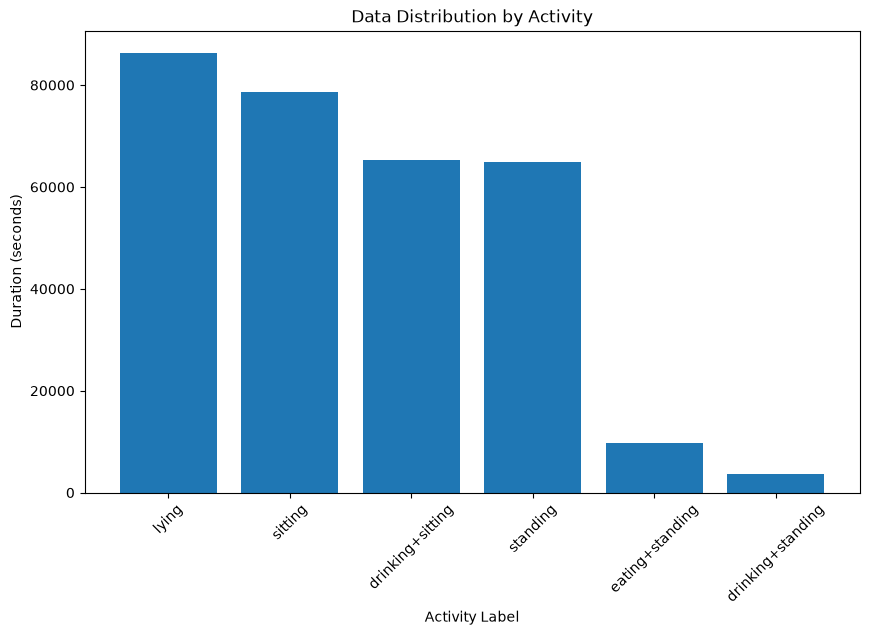

In [20]:
# mimic jeongmin's approach: subsets based on activity label + vizualize the different labels

# available labels in crate8
labels = crate8['activity_label'].unique()
#print(labels) # ['lying' 'Idle' 'sitting' 'drinking+sitting' 'standing' 'eating+standing' 'drinking+standing' nan]

# dropping nan and Idle labels, since we want activities that have vibration data associated with them
labels = [label for label in labels if pd.notna(label) and label != 'Idle']
print(labels) # ['lying', 'sitting', 'drinking+sitting', 'standing', 'eating+standing', 'drinking+standing']

# getting the average duration for each activity label in crate8
activity_durations = {}
for label in labels:
    if pd.isna(label):
        continue
    label_data = crate8[crate8['activity_label'] == label]
    timestamps = pd.to_datetime(
        label_data["timestamp"],
        errors="coerce",
        utc=True,
    ).dropna()

    if timestamps.empty:
        duration = 0.0
    else:
        duration = (
            timestamps.max() - timestamps.min()
        ).total_seconds()
    activity_durations[label] = duration

print(activity_durations) 

# visualize data distribution for each activity label in crate8
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.bar(activity_durations.keys(), activity_durations.values())
plt.xlabel('Activity Label')
plt.ylabel('Duration (seconds)')
plt.title('Data Distribution by Activity')
plt.xticks(rotation=45)
plt.show()

In [ ]:

DATA_FILES = {
    "eating":   pd.read_csv(julia_path + "eating_1000.csv"),
    "drinking": pd.read_csv(julia_path + "drinking_1000.csv"),
    "sitting":  pd.read_csv(julia_path + "sitting_1000.csv"),
    "standing": pd.read_csv(julia_path + "standing_1000.csv"),
}

N_SAMPLES_PER_CLASS = 6000
WINDOW_LENGTH = 100
SENSOR_NUM = 5

In [3]:
def stack_observations(
    X_long,
    y_long=None,
    Window_length = WINDOW_LENGTH
):
    X_long = np.asarray(X_long)
    if y_long is not None:
      y_long = np.asarray(y_long)
    n_sensors = X_long.shape[0]
    Total_length = X_long.shape[1]
    Window_num = Total_length // Window_length;
    X_tall = np.zeros((Window_num*n_sensors, Window_length))
    y_tall = np.full((Window_num*n_sensors, 1), "", dtype=object)
    for i in range(Window_num):
      X_tall[i*n_sensors:(i+1)*n_sensors, :] = X_long[:, i*Window_length:(i+1)*Window_length]
      if y_long is not None:
        y_tall[i*n_sensors:(i+1)*n_sensors, :] = y_long[i*Window_length]
    y_tall = y_tall.flatten()
    return X_tall, y_tall
def reshape_observations(
    X_tall,
    y_tall=None,
    Sensors_num = SENSOR_NUM
):
    X_tall = np.asarray(X_tall)
    if y_tall is not None:
      y_tall = np.asarray(y_tall)
    Window_length = X_tall.shape[1]
    Stacking_num =  X_tall.shape[0]// Sensors_num
    X_long = np.zeros((Sensors_num, Stacking_num*Window_length))
    y_long = np.full((Stacking_num*Window_length, 1), "", dtype=object)
    for i in range(Stacking_num):
      X_long[:, i*Window_length:(i+1)*Window_length] = X_tall[i*Sensors_num:(i+1)*Sensors_num, :]
      if y_tall is not None:
        for j in range(Window_length):
          y_long[i*Window_length+j, :] = y_tall[i*Sensors_num]
    y_long = y_long.flatten()
    return X_long, y_long

In [4]:
# training data is used to estimate matrix S and training AE
training_size = 400000
# If online, part of testing data is used as old data
testing_size = 24000

In [5]:
def load_activity_data(
    data_files=DATA_FILES,
    n_samples_per_class=N_SAMPLES_PER_CLASS,
    n_features=1000,
    Sensor_num = SENSOR_NUM
):
    frames = []
    np.random.seed(100)
    order = np.repeat([0, 1, 2, 3], n_samples_per_class//Sensor_num)
    count = [0, 0, 0, 0]
    np.random.shuffle(order)
    for k in order:
      label, df = list(data_files.items())[k]
      df = df.iloc[:, :n_features].copy()
      df.columns = [f"f{i}" for i in range(n_features)]
      df = df.iloc[Sensor_num*count[k]:Sensor_num*(count[k]+1), :].copy().reset_index(drop=True)
      count[k]+=1
      df["label"] = label
      frames.append(df)

    full = pd.concat(frames, axis=0, ignore_index=True)

    X = full.drop(columns="label").to_numpy(dtype=float)
    y = full["label"].to_numpy()

    X, y = reshape_observations(X, y)

    return X, y, full

def training_testing_partition(
    X,
    y,
    Window_length = WINDOW_LENGTH,
    training_size = training_size,
    testing_size = testing_size,
):
  X = np.asarray(X)
  y = np.asarray(y)
  n_samples = X.shape[1]
  n_train = training_size
  n_test = testing_size
  X_train = X[:, :n_train]
  y_train = y[:n_train]
  random_start_test = np.random.randint(0, math.floor((n_samples-n_train-n_test)/Window_length))*Window_length
  X_test = X[:, n_train+random_start_test:n_train+n_test+random_start_test]
  y_test = y[n_train+random_start_test:n_train+n_test+random_start_test]
  return X_train, y_train, X_test, y_test


In [6]:
# Each row represent data collected from one sensor over time
X, y, _ = load_activity_data()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (5, 4800000)
y shape: (4800000,)


In [7]:
X_train, y_train, X_test, y_test = training_testing_partition(X, y)
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (5, 400000)
y_train shape: (400000,)
X_test shape: (5, 24000)
y_test shape: (24000,)


# 3. Train classifier on complete data

This keeps the classifier fixed during missing-data experiments so the comparison measures robustness to reconstruction rather than retraining.


In [8]:
X_train_stacking, y_train_stacking = stack_observations(X_train, y_train)
X_test_stacking, y_test_stacking = stack_observations(X_test, y_test)

PCA_COMPONENTS = min(50, X_test_stacking.shape[1])

pca_model = PCA(n_components=PCA_COMPONENTS, random_state=42)
X_pca = pca_model.fit_transform(X_test_stacking)

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
    min_samples_leaf=2,
)
rf_model.fit(X_pca, y_test_stacking)


X_pca_test = pca_model.fit_transform(X_test_stacking)
original_pred = rf_model.predict(X_pca_test)
original_accuracy = accuracy_score(y_test_stacking, original_pred)

print(f"Original-data accuracy: {original_accuracy:.9f}")


Original-data accuracy: 0.766666667


In [9]:
print("X_train_stacking shape:", X_train_stacking.shape)
print("y_train_stacking shape:", y_train_stacking.shape)
print("X_test_stacking shape:", X_test_stacking.shape)
print("y_test_stacking shape:", y_test_stacking.shape)

X_train_stacking shape: (20000, 100)
y_train_stacking shape: (20000,)
X_test_stacking shape: (1200, 100)
y_test_stacking shape: (1200,)


# 4. Missing-pattern generators

In [10]:
def generate_multiple_missing_chunks(d, missing_pct, n_chunks=3, rng=None):
    if rng is None:
        rng = np.random.default_rng()

    total_missing = int(round(d * missing_pct))
    total_missing = max(1, min(total_missing, d - 1))

    n_chunks = min(n_chunks, total_missing)

    if n_chunks == 1:
      sizes = [total_missing]
    else:
      cuts = sorted(
          rng.choice(
              np.arange(1, total_missing),
              size=n_chunks - 1,
              replace=False,
          )
      )
      sizes = np.diff([0] + cuts + [total_missing])
    all_placed = False
    while not all_placed:
      mask = np.ones(d, dtype=bool)
      ranges = []
      all_placed = True
      for size in sizes:
        placed = False

        for _ in range(2000):
          start = int(rng.integers(0, d - size + 1))
          end = start + int(size)

          if mask[start:end].all():
            mask[start:end] = False
            ranges.append((start, end))
            placed = True
            break

          if not placed:
            # deterministic fallback: use the first available consecutive block
            available = np.where(mask)[0]
            for start in available:
                end = start + int(size)
                if end <= d and mask[start:end].all():
                    mask[start:end] = False
                    ranges.append((int(start), int(end)))
                    placed = True
                    break

        if not placed:
          all_placed = False
          break
          raise RuntimeError("Could not place non-overlapping missing chunks.")

    observed_idx = np.where(mask)[0]
    missing_idx = np.where(~mask)[0]

    return missing_idx, observed_idx, ranges


def generate_random_missing_entries(d, missing_pct, rng=None):
    if rng is None:
        rng = np.random.default_rng()

    n_missing = int(round(d * missing_pct))
    n_missing = max(1, min(n_missing, d - 1))

    missing_idx = np.sort(
        rng.choice(d, size=n_missing, replace=False)
    )

    mask = np.ones(d, dtype=bool)
    mask[missing_idx] = False
    observed_idx = np.where(mask)[0]

    return missing_idx, observed_idx, None


# 5. Reconstruction


In [11]:
# Control the data size for QPMA training
QPMA_data_size = X_test_stacking.shape[0]

In [12]:
# The row space basis matrix for QPMA, where S = Vt_reference[:r_eff, :]
_, _, Vt_reference = np.linalg.svd(
    X_train_stacking[:QPMA_data_size, :],
    full_matrices=False,
)

In [13]:
print("Vt shape:", Vt_reference.shape)

Vt shape: (100, 100)


In [14]:
def reconstruct_missing_features(
    X,
    observed_idx,
    Vt_reference,
    rank=20,
):
    M = np.zeros_like(X)
    M[:, observed_idx] = 1
    X = np.asarray(X, dtype=float)
    X_obs = X[:, observed_idx];


    if len(observed_idx) == 0:
        raise ValueError("At least one observed feature is required.")

    # Effective rank cannot exceed observed dimension or available SVD basis.
    r_eff = min(
        int(rank),
        Vt_reference.shape[0],
        Vt_reference.shape[1],
    )
    S = Vt_reference[:r_eff, :]

    # step 1: r-svd of X_obs: find colunm space
    U_A, _, _ = np.linalg.svd(
        X_obs,
        full_matrices=False,
    )
    U_r = U_A[:, :r_eff]


    # step 2: find Q and r-svd of QS: find row space
    Q_hat = X_obs @ np.linalg.pinv(S[:, observed_idx])
    # print("QS estimation error:", np.linalg.norm(X-Q_hat@S, ord = 'fro'))
    # print("QS obs estimation error:", np.linalg.norm((X-Q_hat@S)*M, ord = 'fro'))
    _, _, Vt_QS = np.linalg.svd(
      Q_hat@S,
      full_matrices=False,
    )
    Vt_r = Vt_QS[:r_eff, :]

    # step 3: find Z
    # Estimate column space from observed data.
    Z_hat = np.linalg.pinv(U_r) @ X_obs @ np.linalg.pinv(Vt_r[:, observed_idx])
    # print("Z estimation error:", np.linalg.norm(X-U_r@Z_hat@Vt_r, ord = 'fro'))
    # print("Z obs estimation error:", np.linalg.norm((X-U_r@Z_hat@Vt_r)*M, ord = 'fro'))
    X_est = U_r @ Z_hat @ Vt_r
    # print("missing reconstruction norm:", np.linalg.norm(X_est*(1-M), ord = 'fro'))
    # Keep genuinely observed values unchanged.
    X_est = X_est*(1-M) + X*M

    return X_est

# 6. Metrics

In [15]:
def relative_frobenius_error(X_true, X_est):
    denom = np.linalg.norm(X_true, ord="fro")
    return np.linalg.norm(X_true - X_est, ord="fro") / denom


def missing_only_relative_error_M(X_true, X_est, M):
    X_true = np.asarray(X_true, dtype=float)
    X_est = np.asarray(X_est, dtype=float)
    X_true_m = X_true*(1-M)
    X_est_m = X_est*(1-M)

    denom = np.linalg.norm(X_true_m, ord="fro")
    if denom == 0:
        return np.nan

    return np.linalg.norm(X_true_m - X_est_m, ord="fro") / denom


def classification_accuracy(X_est, y, pca_model, classifier):
    X_est_pca = pca_model.transform(X_est)
    pred = classifier.predict(X_est_pca)
    return accuracy_score(y, pred)


# 7. One-call experiment

Use:

```python
result = run_missing_reconstruction(
    missing_pct=0.30,
    mode="chunks",
    rank=20,
)
```


In [16]:
def run_missing_reconstruction(
    missing_pct,
    mode="chunks",
    rank=20,
    n_chunks=3,
    seed=42,
    X=X_test_stacking,
    y=y_test_stacking,
    Vt_reference=Vt_reference,
    pca_model=pca_model,
    classifier=rf_model,
    predict_with_missing=False,
    Online = False,
):
    rng = np.random.default_rng(seed)
    # d = WINDOW_LENGTH, we sample missing column index among [0, 1, ..., d-1]
    d = X.shape[1]

    if mode == "chunks":
        missing_idx, observed_idx, missing_ranges = (
            generate_multiple_missing_chunks(
                d=d,
                missing_pct=missing_pct,
                n_chunks=n_chunks,
                rng=rng,
            )
        )
    elif mode == "random":
        missing_idx, observed_idx, missing_ranges = (
            generate_random_missing_entries(
                d=d,
                missing_pct=missing_pct,
                rng=rng,
            )
        )
    else:
        raise ValueError("mode must be 'chunks' or 'random'")

    # Equivalent zero masking matrix for colunm missing
    M = np.ones_like(X)
    M[:, missing_idx] = 0


    if predict_with_missing:
      X_est = X*M
    else:
      X_est = reconstruct_missing_features(
          X=X,
          observed_idx = observed_idx,
          Vt_reference=Vt_reference,
          rank=rank,
      )

    if Online:
      accuracy = classification_accuracy(
          X_est=X_est[-5:, :],
          y=y[-5:],
          pca_model=pca_model,
          classifier=classifier,
      )
    else:
      accuracy = classification_accuracy(
          X_est=X_est,
          y=y,
          pca_model=pca_model,
          classifier=classifier,
      )

    result = {
        "missing_pct": float(missing_pct),
        "mode": mode,
        "rank": int(rank),
        "missing_idx": missing_idx,
        "observed_idx": observed_idx,
        "zero_mask": M,
        "missing_ranges": missing_ranges,
        "X": X,
        "X_est": X_est,
        "accuracy": float(accuracy),
        "relative_error": float(
            relative_frobenius_error(X, X_est)
        ),
        "missing_only_error": float(
            relative_frobenius_error(X*(1-M), X_est*(1-M))
        ),
        "observed_only_error": float(
            relative_frobenius_error(X*M, X_est*M)
        ),
    }

    return result


# 8. Automatically sweep missing percentages

In [17]:
def sweep_missing_percentages(
    missing_pcts=(0.10, 0.20, 0.30, 0.40, 0.50),
    mode="chunks",
    rank=20,
    n_chunks=3,
    n_trials=5,
    base_seed=42,
    Online = False,
):
    summary_rows = []
    all_results = {}

    for pct in missing_pcts:
        pct_results = []

        for trial in range(n_trials):
            result = run_missing_reconstruction(
                missing_pct=pct,
                mode=mode,
                rank=rank,
                n_chunks=n_chunks,
                seed=base_seed + trial,
                Online = Online,
            )
            pct_results.append(result)

        all_results[pct] = pct_results

        summary_rows.append({
            "missing_pct": pct,
            "missing_percent": int(round(100 * pct)),
            "rank": rank,
            "mode": mode,
            "mean_accuracy": np.mean(
                [r["accuracy"] for r in pct_results]
            ),
            "std_accuracy": np.std(
                [r["accuracy"] for r in pct_results]
            ),
            "mean_relative_error": np.mean(
                [r["relative_error"] for r in pct_results]
            ),
            "mean_missing_only_error": np.mean(
                [r["missing_only_error"] for r in pct_results]
            ),
        })

    summary = pd.DataFrame(summary_rows)
    return summary, all_results


In [18]:
summary, all_results = sweep_missing_percentages(
    missing_pcts=[0.10, 0.20, 0.30, 0.40, 0.50],
    mode="chunks",      # change to "random" if needed
    rank=20,
    n_chunks=3,
    n_trials=100,       # If it takes too long to run, adjust the number of experiments, n_trials
    Online = False,
)

summary


,missing_pct,missing_percent,rank,mode,mean_accuracy,std_accuracy,mean_relative_error,mean_missing_only_error
0,0.1,10,20,chunks,0.712975,0.020103,0.001261,0.003792
1,0.2,20,20,chunks,0.619850,0.040547,0.002994,0.006041
2,0.3,30,20,chunks,0.539283,0.047875,0.005174,0.008382
3,0.4,40,20,chunks,0.479208,0.053990,0.008819,0.012065
4,0.5,50,20,chunks,0.419975,0.064374,0.093078,0.102318


In [19]:
import pickle
summary.to_pickle("summary.pkl")

# 9. Plot automated results

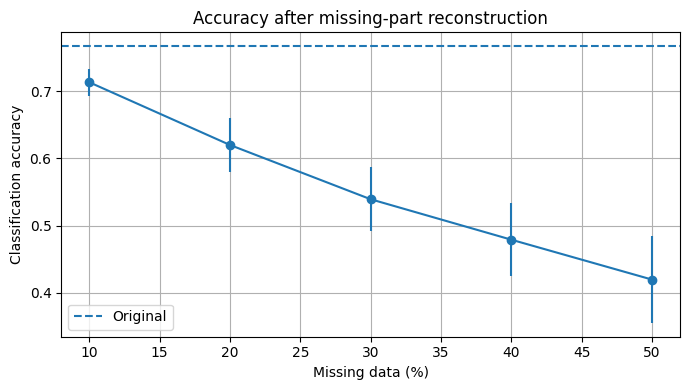

In [20]:
plt.figure(figsize=(7, 4))
plt.errorbar(
    summary["missing_percent"],
    summary["mean_accuracy"],
    yerr=summary["std_accuracy"],
    marker="o",
)
plt.axhline(
    original_accuracy,
    linestyle="--",
    label="Original",
)
plt.xlabel("Missing data (%)")
plt.ylabel("Classification accuracy")
plt.title("Accuracy after missing-part reconstruction")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


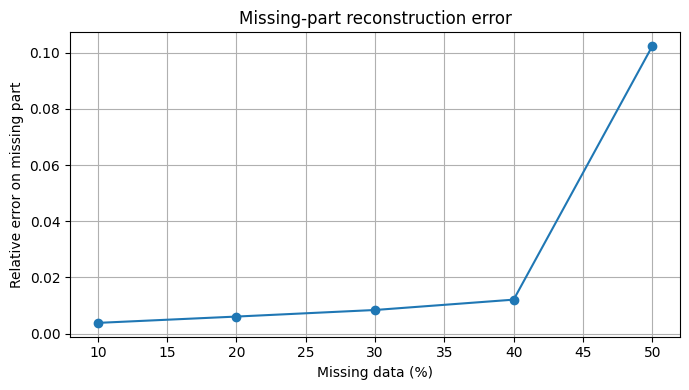

In [21]:
plt.figure(figsize=(7, 4))
plt.plot(
    summary["missing_percent"],
    summary["mean_missing_only_error"],
    marker="o",
)
plt.xlabel("Missing data (%)")
plt.ylabel("Relative error on missing part")
plt.title("Missing-part reconstruction error")
plt.grid(True)
plt.tight_layout()
plt.show()


# 10. Inspect one reconstruction

Choose a missing percentage and trial. This automatically plots the true signal, zero-filled signal, and reconstructed signal averaged across samples.


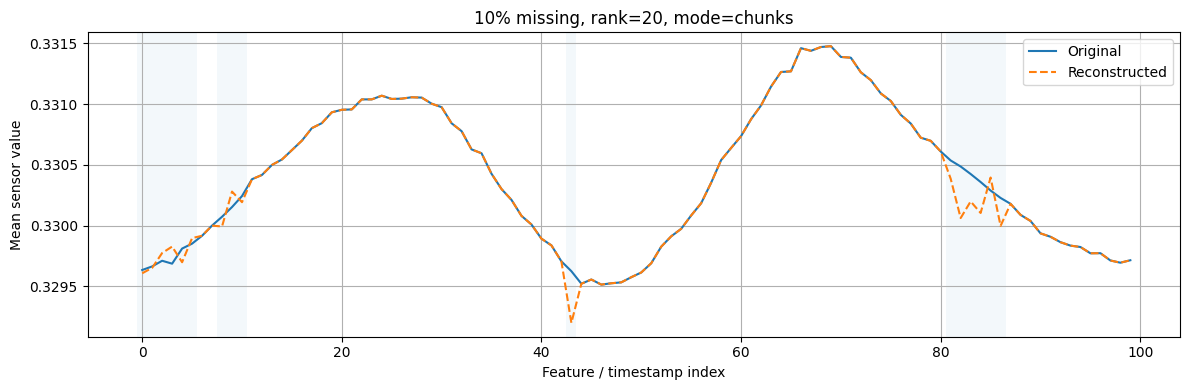

In [22]:
def plot_reconstruction(result, X_true=X_test_stacking):
    X_est = result["X_est"]
    # X_est, _ = reshape_observations(X_est)
    # X_zero = result["X_zero"]
    missing_idx = result["missing_idx"]

    true_mean = X_true.mean(axis=0)
    #zero_mean = X_zero.mean(axis=0)
    est_mean = X_est.mean(axis=0)

    plt.figure(figsize=(12, 4))
    plt.plot(true_mean, label="Original")
    #plt.plot(zero_mean, "--", label="Zero-filled")
    plt.plot(est_mean, "--", label="Reconstructed")

    for idx in missing_idx:
        plt.axvspan(
            idx - 0.5,
            idx + 0.5,
            alpha=0.05,
        )

    plt.xlabel("Feature / timestamp index")
    plt.ylabel("Mean sensor value")
    plt.title(
        f'{int(result["missing_pct"]*100)}% missing, '
        f'rank={result["rank"]}, mode={result["mode"]}'
    )
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()
    # print(est_mean)


example = all_results[0.10][0]
plot_reconstruction(example)


# 11. Save reconstructed matrices automatically

This prevents reconstructed outputs from being lost or overwritten between experiments.


In [23]:
from pathlib import Path

def save_reconstruction_results(
    all_results,
    output_dir="reconstruction_outputs",
):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    for pct, results in all_results.items():
        pct_int = int(round(100 * pct))

        for trial, result in enumerate(results):
            filename = (
                output_dir
                / f"X_est_missing_{pct_int:02d}pct_trial_{trial:02d}.npy"
            )
            np.save(filename, result["X_est"])

    print(f"Saved results to: {output_dir.resolve()}")


# Uncomment when you want to save all reconstructed matrices.
# save_reconstruction_results(all_results)


# 12. Optional: rank sweep

This automates the original manual comparisons across reconstruction ranks.


In [24]:
def sweep_ranks(
    ranks=(5, 7, 10, 20, 50, 80),
    missing_pcts=(0.10, 0.20, 0.30, 0.40, 0.50),
    mode="chunks",
    n_trials=3,
):
    tables = []

    for rank in ranks:
        rank_summary, _ = sweep_missing_percentages(
            missing_pcts=missing_pcts,
            mode=mode,
            rank=rank,
            n_trials=n_trials,
        )
        tables.append(rank_summary)

    return pd.concat(tables, ignore_index=True)


# Example:
# rank_summary = sweep_ranks()
# rank_summary


# 13. Notes on changes from the original notebook

The original notebook had several fragile points that are removed here:

- `d=1000` was hard-coded even though the loaded feature count could differ.
- `mask = np.ones(1000)` was hard-coded.
- `X_original` and `X_ori` were used inconsistently.
- reconstructed matrices were overwritten between trials.
- PCA was refit during reconstruction evaluation, which makes comparison harder to interpret.
- many missing percentages/ranks were entered manually.

This version infers dimensions from the data, keeps the PCA/classifier fixed, and returns every reconstruction in a structured result dictionary.


# 14. Autoencoder reconstruction from zero-filled missing data

A **denoising autoencoder** is a natural baseline for this experiment.

Training strategy:

1. Start from complete training samples.
2. Randomly mask part of each sample.
3. Replace masked entries with **0**.
4. Feed the zero-filled vector to the autoencoder.
5. Use the complete original vector as the reconstruction target.

At test time, the real missing locations are also zero-filled before being passed to the autoencoder.

The version below also concatenates the binary observation mask to the input. This helps the network distinguish a genuinely observed zero from a zero that represents missing data.


In [25]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)


Using device: cpu


# 15. Mask-aware denoising autoencoder

In [26]:
class MaskAwareAutoencoder(nn.Module):
    def __init__(self, input_dim, latent_dim=32):
        super().__init__()

        # Input = [zero-filled data, binary mask]
        self.encoder = nn.Sequential(
            nn.Linear(input_dim * 2, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, latent_dim),
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, input_dim),
        )

    def forward(self, x_zero, mask):
        x_in = torch.cat([x_zero, mask], dim=1)
        z = self.encoder(x_in)
        return self.decoder(z)


# 16. Generate zero-filled training corruptions

Each minibatch receives a newly generated random mask.  
This prevents the network from memorizing one fixed missing pattern.


In [27]:
def make_random_zero_mask(
    x,
    missing_pct_min=0.10,
    missing_pct_max=0.50,
):
    batch_size, d = x.shape

    masks = torch.ones_like(x)

    for i in range(batch_size):
        pct = np.random.uniform(
            missing_pct_min,
            missing_pct_max,
        )
        n_missing = max(
            1,
            int(round(d * pct)),
        )

        idx = np.random.choice(
            d,
            size=n_missing,
            replace=False,
        )
        masks[i, idx] = 0.0

    x_zero = x * masks

    return x_zero, masks


# 17. Train the denoising autoencoder

The loss gives extra weight to the masked entries because those are the values we actually care about reconstructing.


In [28]:
def train_autoencoder(
    X,
    latent_dim=32,
    epochs=100,
    batch_size=125,
    learning_rate=1e-3,
    missing_pct_min=0.10,
    missing_pct_max=0.50,
    missing_weight=5.0,
):
    X_tensor = torch.tensor(
        X,
        dtype=torch.float32,
    )

    loader = DataLoader(
        TensorDataset(X_tensor),
        batch_size=batch_size,
        shuffle=True,
    )

    model = MaskAwareAutoencoder(
        input_dim=X.shape[1],
        latent_dim=latent_dim,
    ).to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate,
    )

    mse = nn.MSELoss(reduction="none")

    history = []

    for epoch in range(epochs):
        model.train()
        epoch_loss = 0.0
        # if epoch%100 == 0:
        #   X = X_train[epoch//100]
        #   X_tensor = torch.tensor(
        #     X,
        #     dtype=torch.float32,
        #   )
        #   loader = DataLoader(
        #     TensorDataset(X_tensor),
        #     batch_size=batch_size,
        #     shuffle=True,
        #   )
        for (x_true,) in loader:
            x_true = x_true.to(device)
            x_zero, mask = make_random_zero_mask(
                x_true,
                missing_pct_min=missing_pct_min,
                missing_pct_max=missing_pct_max,
            )

            x_hat = model(
                x_zero,
                mask,
            )

            element_loss = mse(
                x_hat,
                x_true,
            )

            # Missing entries get larger weight.
            weights = (
                mask
                + missing_weight * (1.0 - mask)
            )

            loss = (
                element_loss * weights
            ).mean()

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            epoch_loss += (
                loss.item() * x_true.size(0)
            )

        epoch_loss /= len(X_tensor)
        history.append(epoch_loss)

        if (
            epoch == 0
            or (epoch + 1) % 10 == 0
        ):
            print(
                f"Epoch {epoch+1:3d}/{epochs} "
                f"- loss: {epoch_loss:.6f}"
            )

    return model, history


In [29]:
# Control the data size for AE training
AE_data_size = min(QPMA_data_size*5, X_training_stacking.shape[0])

In [30]:
ae_model, ae_history = train_autoencoder(
    X_train_stacking[:AE_data_size, :],
    latent_dim=16,
    epochs=1000,
    batch_size=50,
    learning_rate=1e-3,
    missing_pct_min=0.10,
    missing_pct_max=0.50,
)


Epoch   1/1000 - loss: 0.056175
Epoch  10/1000 - loss: 0.000508
Epoch  20/1000 - loss: 0.000530
Epoch  30/1000 - loss: 0.000539
Epoch  40/1000 - loss: 0.000510
Epoch  50/1000 - loss: 0.000557
Epoch  60/1000 - loss: 0.000526
Epoch  70/1000 - loss: 0.000515
Epoch  80/1000 - loss: 0.000534
Epoch  90/1000 - loss: 0.000496
Epoch 100/1000 - loss: 0.000430
Epoch 110/1000 - loss: 0.000398
Epoch 120/1000 - loss: 0.000407
Epoch 130/1000 - loss: 0.000401
Epoch 140/1000 - loss: 0.000383
Epoch 150/1000 - loss: 0.000441
Epoch 160/1000 - loss: 0.000392
Epoch 170/1000 - loss: 0.000377
Epoch 180/1000 - loss: 0.000351
Epoch 190/1000 - loss: 0.000446
Epoch 200/1000 - loss: 0.000398
Epoch 210/1000 - loss: 0.000368
Epoch 220/1000 - loss: 0.000355
Epoch 230/1000 - loss: 0.000339
Epoch 240/1000 - loss: 0.000317
Epoch 250/1000 - loss: 0.000373
Epoch 260/1000 - loss: 0.000360
Epoch 270/1000 - loss: 0.000350
Epoch 280/1000 - loss: 0.000345
Epoch 290/1000 - loss: 0.000303
Epoch 300/1000 - loss: 0.000299
Epoch 31

In [31]:
torch.save(ae_model.state_dict(), "ae_model.pth")

# 18. Reconstruct a specified missing pattern

In [32]:
def reconstruct_with_autoencoder(
    model,
    X,
    missing_idx,
):
    model.eval()

    # X_zero, data matrix with missing columns
    X_zero = X.copy()
    X_zero[:, missing_idx] = 0.0

    mask = np.ones_like(X_zero)
    mask[:, missing_idx] = 0.0

    x_zero_t = torch.tensor(
        X_zero,
        dtype=torch.float32,
        device=device,
    )

    mask_t = torch.tensor(
        mask,
        dtype=torch.float32,
        device=device,
    )

    with torch.no_grad():
        X_ae = model(
            x_zero_t,
            mask_t,
        ).cpu().numpy()

    # Keep observed entries exactly unchanged.
    X_reconstructed = X_zero.copy()
    X_reconstructed[:, missing_idx] = (
        X_ae[:, missing_idx]
    )

    return X_reconstructed, X_zero


# 19. One-call AE missing-reconstruction experiment

This uses the same missing-pattern generators and evaluation metrics as the earlier reconstruction method, so the comparison is fair.


In [33]:
def run_autoencoder_missing_reconstruction(
    missing_pct,
    mode="chunks",
    n_chunks=3,
    seed=42,
    model=ae_model,
    X=X_test_stacking,
    y=y_test_stacking,
):
    rng = np.random.default_rng(seed)
    d = X.shape[1]

    if mode == "chunks":
        missing_idx, observed_idx, missing_ranges = (
            generate_multiple_missing_chunks(
                d=d,
                missing_pct=missing_pct,
                n_chunks=n_chunks,
                rng=rng,
            )
        )

    elif mode == "random":
        missing_idx, observed_idx, missing_ranges = (
            generate_random_missing_entries(
                d=d,
                missing_pct=missing_pct,
                rng=rng,
            )
        )

    else:
        raise ValueError(
            "mode must be 'chunks' or 'random'"
        )

    X_est, X_zero = (
        reconstruct_with_autoencoder(
            model=model,
            X=X,
            missing_idx=missing_idx,
        )
    )
    if X.shape != X_est.shape:
      raise ValueError(
              "Shape mismatch"
          )
    accuracy = classification_accuracy(
        X_est=X_est,
        y=y,
        pca_model=pca_model,
        classifier=rf_model,
    )

    M = np.ones_like(X)
    M[:, missing_idx] = 0

    return {
        "missing_pct": float(missing_pct),
        "mode": mode,
        "missing_idx": missing_idx,
        "observed_idx": observed_idx,
        "zero_mask": M,
        "missing_ranges": missing_ranges,
        "X": X,
        "X_est": X_est,
        "accuracy": float(accuracy),
        "relative_error": float(
            relative_frobenius_error(X, X_est)
        ),
        "missing_only_error": float(
            relative_frobenius_error(X*(1-M), X_est*(1-M))
        ),
        "observed_only_error": float(
            relative_frobenius_error(X*M, X_est*M)
        ),
    }


# 20. Automatically sweep AE reconstruction

In [34]:
def sweep_autoencoder_missing(
    missing_pcts=(0.10, 0.20, 0.30, 0.40, 0.50),
    mode="chunks",
    n_chunks=3,
    n_trials=5,
    base_seed=42,
):
    rows = []
    all_ae_results = {}

    for pct in missing_pcts:
        results = []

        for trial in range(n_trials):
            result = (
                run_autoencoder_missing_reconstruction(
                    missing_pct=pct,
                    mode=mode,
                    n_chunks=n_chunks,
                    seed=base_seed + trial,
                )
            )
            results.append(result)

        all_ae_results[pct] = results

        rows.append({
            "missing_pct": pct,
            "missing_percent": int(
                round(100 * pct)
            ),
            "mode": mode,
            "mean_accuracy": np.mean(
                [
                    r["accuracy"]
                    for r in results
                ]
            ),
            "std_accuracy": np.std(
                [
                    r["accuracy"]
                    for r in results
                ]
            ),
            "mean_relative_error": np.mean(
                [
                    r["relative_error"]
                    for r in results
                ]
            ),
            "mean_missing_only_error": np.mean(
                [
                    r["missing_only_error"]
                    for r in results
                ]
            ),
        })

    return (
        pd.DataFrame(rows),
        all_ae_results,
    )


ae_summary, ae_all_results = (
    sweep_autoencoder_missing(
        missing_pcts=[
            0.10,
            0.20,
            0.30,
            0.40,
            0.50
        ],
        mode="chunks",
        n_chunks=3,
        n_trials=100,
    )
)

ae_summary


,missing_pct,missing_percent,mode,mean_accuracy,std_accuracy,mean_relative_error,mean_missing_only_error
0,0.1,10,chunks,0.380300,0.044368,0.005487,0.016712
1,0.2,20,chunks,0.327792,0.035783,0.008129,0.016740
2,0.3,30,chunks,0.309917,0.033379,0.010181,0.016805
3,0.4,40,chunks,0.296600,0.028046,0.013581,0.018813
4,0.5,50,chunks,0.278475,0.039143,0.030325,0.035460


In [35]:
ae_summary.to_pickle("ae_summary.pkl")

# 21. Compare subspace reconstruction vs autoencoder

In [36]:
comparison = summary[
    [
        "missing_percent",
        "mean_accuracy",
        "mean_missing_only_error",
    ]
].rename(
    columns={
        "mean_accuracy":
            "Subspace accuracy",
        "mean_missing_only_error":
            "Subspace missing error",
    }
).merge(
    ae_summary[
        [
            "missing_percent",
            "mean_accuracy",
            "mean_missing_only_error",
        ]
    ].rename(
        columns={
            "mean_accuracy":
                "AE accuracy",
            "mean_missing_only_error":
                "AE missing error",
        }
    ),
    on="missing_percent",
)

comparison


,missing_percent,Subspace accuracy,Subspace missing error,AE accuracy,AE missing error
0,10,0.712975,0.003792,0.380300,0.016712
1,20,0.619850,0.006041,0.327792,0.016740
2,30,0.539283,0.008382,0.309917,0.016805
3,40,0.479208,0.012065,0.296600,0.018813
4,50,0.419975,0.102318,0.278475,0.035460


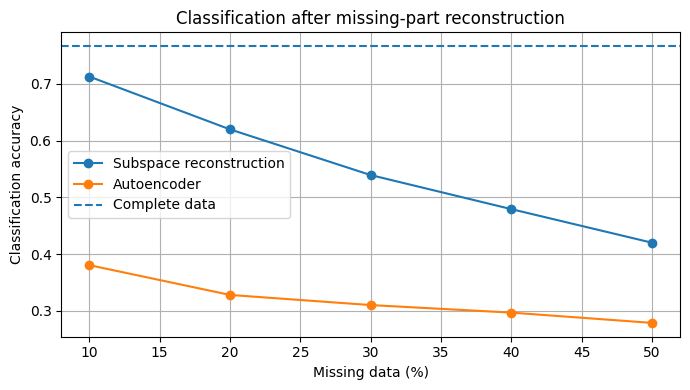

In [37]:
plt.figure(figsize=(7, 4))

plt.plot(
    comparison["missing_percent"],
    comparison["Subspace accuracy"],
    marker="o",
    label="Subspace reconstruction",
)

plt.plot(
    comparison["missing_percent"],
    comparison["AE accuracy"],
    marker="o",
    label="Autoencoder",
)

plt.axhline(
    original_accuracy,
    linestyle="--",
    label="Complete data",
)

plt.xlabel("Missing data (%)")
plt.ylabel("Classification accuracy")
plt.title(
    "Classification after missing-part reconstruction"
)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


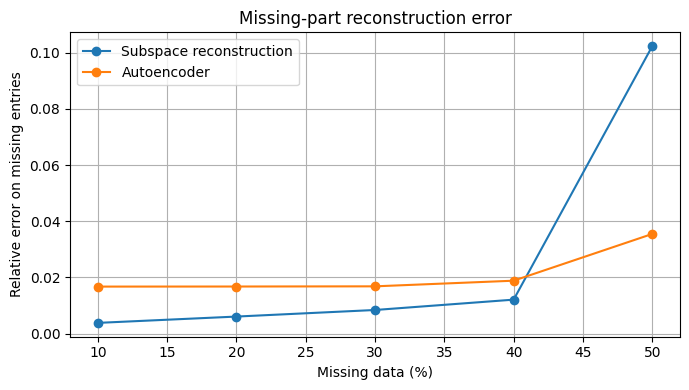

In [38]:
plt.figure(figsize=(7, 4))

plt.plot(
    comparison["missing_percent"],
    comparison["Subspace missing error"],
    marker="o",
    label="Subspace reconstruction",
)

plt.plot(
    comparison["missing_percent"],
    comparison["AE missing error"],
    marker="o",
    label="Autoencoder",
)

plt.xlabel("Missing data (%)")
plt.ylabel("Relative error on missing entries")
plt.title(
    "Missing-part reconstruction error"
)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# 22. Real vs estimated activity-signal comparison

This figure reproduces the style of the reference plot:

- solid line = real data
- dashed line = reconstructed / estimated data
- Eating, Drinking, Sitting, and Standing are shown together

The function below can use either the autoencoder reconstruction or the subspace reconstruction result.


In [39]:
ACTIVITY_ORDER = ["eating", "drinking", "sitting", "standing"]

def get_activity_indices(y, activity):
    return np.where(np.asarray(y) == activity)[0]


def activity_mean_signal(X, y, activity):
    idx = get_activity_indices(y, activity)
    if len(idx) == 0:
        raise ValueError(f"No samples found for activity: {activity}")
    return X[idx].mean(axis=0)


In [40]:
def plot_real_vs_estimated_activities(
    X_true,
    X_est,
    y,
    activities=ACTIVITY_ORDER,
    start=0,
    end=None,
    title="Signal comparison between real data and estimated data",
):
    if end is None:
        end = X_true.shape[1]

    start = max(0, int(start))
    end = min(int(end), X_true.shape[1])

    plt.figure(figsize=(14, 5))

    # Real signals
    for activity in activities:
        real_signal = activity_mean_signal(
            X_true,
            y,
            activity,
        )
        plt.plot(
            np.arange(start, end),
            real_signal[start:end],
            label=activity.capitalize(),
        )

    # Estimated signals
    for activity in activities:
        est_signal = activity_mean_signal(
            X_est,
            y,
            activity,
        )
        plt.plot(
            np.arange(start, end),
            est_signal[start:end],
            "--",
            label=f"{activity.capitalize()} (Estimated)",
        )

    plt.xlabel("Timestamp")
    plt.ylabel("Normalized sensor value")
    plt.title(title)
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()


## Autoencoder example

Choose any missing percentage and trial from `all_ae_results`.


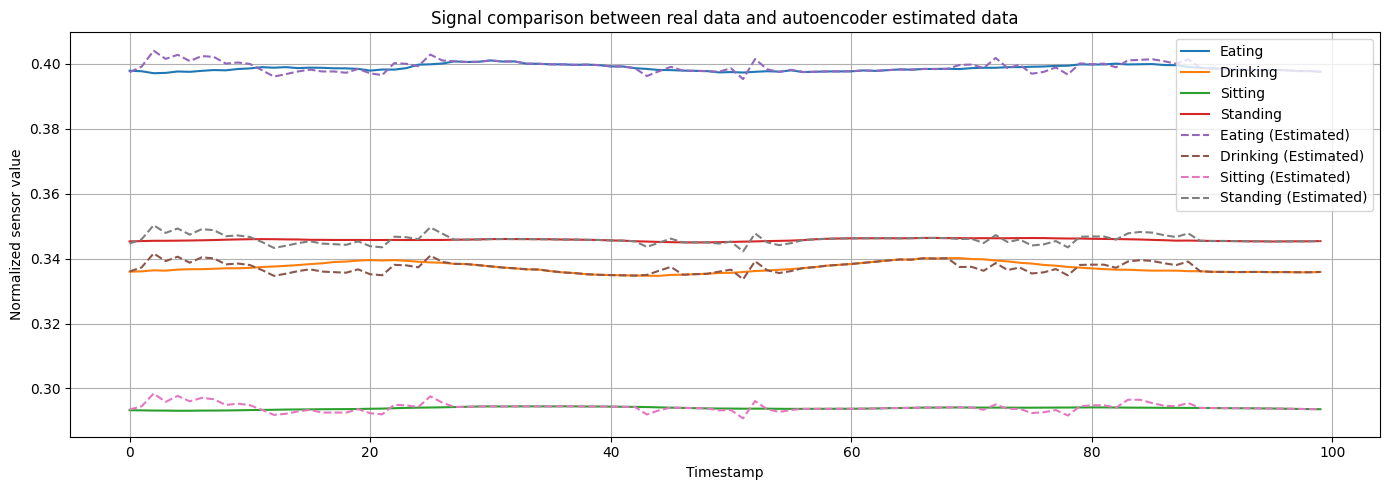

In [41]:
# Example: 30% missing, first trial
ae_example = ae_all_results[0.30][0]

plot_real_vs_estimated_activities(
    X_true=X_test_stacking,
    X_est=ae_example["X_est"],
    y=y_test_stacking,
    start=0,
    end=min(200, X_test.shape[1]),
    title="Signal comparison between real data and autoencoder estimated data",
)


## Subspace-reconstruction example

The same visualization can be used with the earlier reconstruction method.


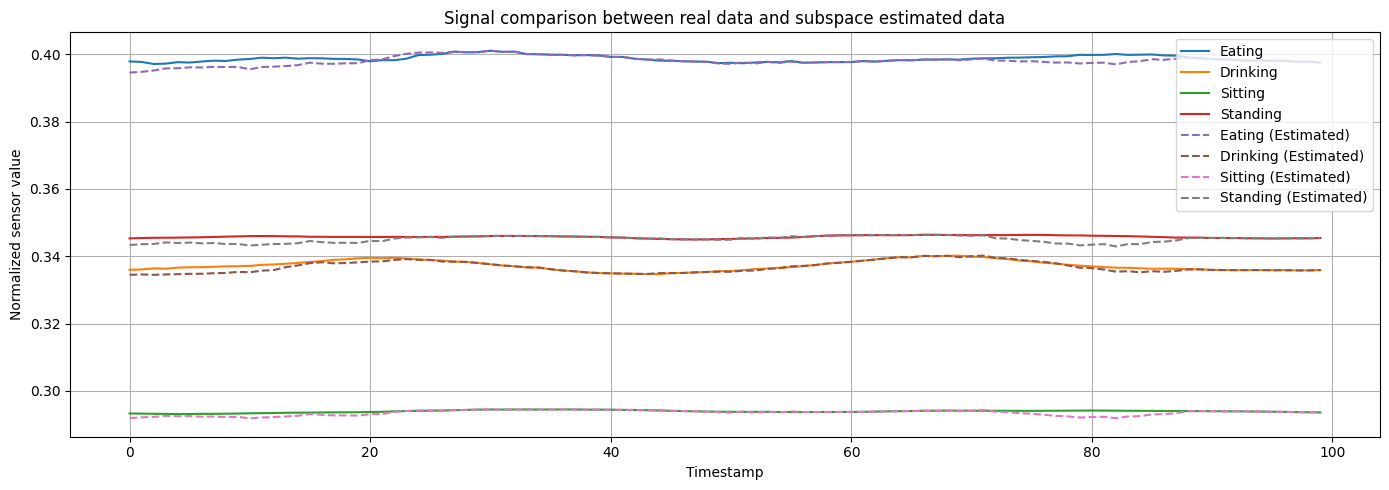

In [42]:
subspace_example = all_results[0.30][0]

plot_real_vs_estimated_activities(
    X_true=X_test_stacking,
    X_est=subspace_example["X_est"],
    y=y_test_stacking,
    start=0,
    end=min(200, X_test.shape[1]),
    title="Signal comparison between real data and subspace estimated data",
)


## Compare different missing percentages automatically

This makes one figure per missing percentage using the first stored trial.


In [43]:
def plot_activity_reconstruction_sweep(
    results_dict,
    X_true=X_test,
    y=y_test,
    method_name="Estimated",
    start=0,
    end=None,
):
    for pct in sorted(results_dict.keys()):
        result = results_dict[pct][0]

        plot_real_vs_estimated_activities(
            X_true=X_true,
            X_est=result["X_est"],
            y=y,
            start=start,
            end=end,
            title=(
                f"Real vs {method_name} signal "
                f"({int(round(100*pct))}% missing)"
            ),
        )


# Autoencoder:
# plot_activity_reconstruction_sweep(
#     all_ae_results,
#     method_name="Autoencoder",
#     start=0,
#     end=min(200, X_original.shape[1]),
# )

# Subspace:
# plot_activity_reconstruction_sweep(
#     all_results,
#     method_name="Subspace",
#     start=0,
#     end=min(200, X_original.shape[1]),
# )
